In [530]:
%matplotlib inline
import time
from Gaussian_Quadrature import gauss_radau_left
import matplotlib.pyplot as plt
import scipy as sp
import numpy as np
from scipy import linalg, interpolate, integrate
from IPython.display import clear_output
from scipy.integrate import solve_ivp
from scipy.interpolate import BarycentricInterpolator
from scipy.optimize import minimize
from scipy.linalg import solve_continuous_are
from numpy.polynomial.legendre import leggauss
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as CK, WhiteKernel
import warnings

In [531]:
n_states = 3
n_inputs = 1
n_outputs = 1

In [532]:
beta = 20.0 

# The Full-Order Model (FOM) is defined by
# dx/dt = Ax + Bu + einsum('ijk,j,k', H, x, x) + einsum('i, ijk, k', N, u, x)
# y = Cx

## linear part of FOM
A_FOM = np.array([[-1.0, 0.0, 0.0], \
                  [0.0, -2.0, 0.0], \
                  [0.0, 0.0, -5.0]])

B_FOM = np.array([[1.0], \
                  [1.0], \
                  [1.0]])

C_FOM = np.array([[1.0, 1.0, 1.0]])

## nonlinear part of FOM
H_FOM = np.zeros((n_states, n_states, n_states))
H_FOM[0, 0, 2] = beta
H_FOM[1, 1, 2] = beta

# symmetrize the quadratic term
H_FOM = (H_FOM + np.transpose(H_FOM, axes=(0,2,1))) / 2.0

N_FOM = np.zeros((n_states, n_inputs, n_states))

# full-order model
def FOM(x, u):
    f = np.einsum('ij,...j', A_FOM, x) + np.einsum('ij,...j', B_FOM, u) + \
        np.einsum('ijk,...j,...k', H_FOM, x, x) + np.einsum('ijk,...j,...k', N_FOM, u, x)
    return f

# observation function
def FOM_obs(x):
    g = np.einsum('ij,...j', C_FOM, x)
    return g

# derivative of full-order model acting on v
def d_FOM(x, u, v):
    df_v = np.einsum('ij,...j', A_FOM, v) + \
        2.0*np.einsum('ijk,...j,...k', H_FOM, x, v) + np.einsum('ijk,...j,...k', N_FOM, u, v)
    return df_v

# derivative of observation function acting on v
def d_FOM_obs(x, v):
    dg_v = np.einsum('ij,...j', C_FOM, v)
    return dg_v

# adjoint of FOM acting on w
def d_FOM_adj(x, u, w):
    df_T_w = np.einsum('ji,...j', A_FOM, w) + \
        2.0*np.einsum('kji,...j,...k', H_FOM, x, w) + np.einsum('kji,...j,...k', N_FOM, u, w)
    return df_T_w

# adjoint of observations acting on w
def d_FOM_obs_adj(x, w):
    dg_T_w = np.einsum('ji,...j', C_FOM, w)
    return dg_T_w

In [533]:
# step size for finite differences
eps = 1.0e-8

# random state and input
x = np.random.randn(n_states)
u = np.random.randn(n_inputs)

# random vector tangent to state
v = np.random.randn(n_states)

# validate derivative of FOM and observation function
df_v_FD = (FOM(x+eps*v,u) - FOM(x,u))/eps
df_v = d_FOM(x,u,v)
print(f"Relative error for FOM derivative: {np.linalg.norm(df_v - df_v_FD) / np.linalg.norm(df_v_FD):.3e}")

dg_v_FD = (FOM_obs(x+eps*v) - FOM_obs(x))/eps
dg_v = d_FOM_obs(x,v)
print(f"Relative error for observation derivative: {np.linalg.norm(dg_v - dg_v_FD) / np.linalg.norm(dg_v_FD):.3e}")

# random vector tangent to state
w = np.random.randn(n_states)

# validate adjoint of derivative of FOM using definition of adjoint
IP1 = np.dot(d_FOM(x,u,v), w)
IP2 = np.dot(v, d_FOM_adj(x,u,w))
print(f"Adjoint consistency check for FOM derivative: {np.linalg.norm(IP2 - IP1)/np.linalg.norm(IP1):.3e}")

# random vector tangent to output
w = np.random.randn(n_outputs)

# validate adjoint of derivative of observation function using definition of adjoint
IP1 = np.dot(d_FOM_obs(x,v), w)
IP2 = np.dot(v, d_FOM_obs_adj(x,w))
print(f"Adjoint consistency check for observation derivative: {np.linalg.norm(IP2 - IP1)/np.linalg.norm(IP1):.3e}")

Relative error for FOM derivative: 1.022e-08
Relative error for observation derivative: 2.954e-09
Adjoint consistency check for FOM derivative: 1.705e-16
Adjoint consistency check for observation derivative: 1.127e-16


In [534]:
# ORIGINAL SET OF INITIAL CONDITION
# set tolerance for solvers
atol = 1.0e-9
rtol = 1.0e-7
solver_method = 'RK45'

In [535]:
# number of trajectories
np.random.seed(24)
n_traj = 2
traj_ICs = np.array([np.random.uniform(0.5, 1.0, size=n_states) for _ in range(n_traj)])

In [536]:
# # Plot the initial conditions
# fig = plt.figure()
# ax = fig.add_subplot(111, projection='3d')

# ax.scatter(traj_ICs[:, 0], traj_ICs[:, 1], traj_ICs[:, 2])
# ax.set_xlabel('x_1(0)')
# ax.set_ylabel('x_2(0)')
# ax.set_zlabel('x_3(0)')
# ax.set_title('Training initial conditions for the toy model')

# plt.show()

In [537]:
# Create a common time grid and zero-control input for each trajectory.
# The model is simulated over the interval [0, 10] with 1001 time points.
traj_time = np.linspace(0, 10.0, 1001)  # 1000 time steps

# Use zero control input for all trajectories.
u_trajs = [np.reshape(0.0 * traj_time, (-1, 1)) for k in range(n_traj)]

# Alternative control choices for testing:
# u_trajs = [np.reshape(np.sin(traj_time), (-1, 1)) for k in range(n_traj)]
# u_trajs = [np.ones((len(traj_time), 1)) for k in range(n_traj)]

# Storage arrays for the simulated state and output trajectories.
FOM_x_trajs = [_ for _ in range(n_traj)]
FOM_y_trajs = [_ for _ in range(n_traj)]

In [538]:
for k in range(n_traj):
    # interpolate the input
    u_fun = sp.interpolate.interp1d(traj_time, u_trajs[k], axis=0)
    
    # initial condition
    x0 = traj_ICs[k]
    
    # simulate the FOM
    sol = sp.integrate.solve_ivp(lambda t,x: FOM(x, u_fun(t)), \
                                 # jac = lambda t,x: d_FOM(x, u_fun(t), np.eye(n_states)), \
                                 t_span = [traj_time[0], traj_time[-1]], \
                                 y0 = x0, \
                                 t_eval = traj_time, \
                                 method = solver_method, \
                                 atol=atol, rtol=rtol)
    
    # This overwrites the stored state and output trajectories for each new initial condition.
    FOM_x_trajs[k] = sol.y.T
    FOM_y_trajs[k] = FOM_obs(sol.y.T)

In [539]:
# This keeps every 100th time point for downsampling trajectories.
sample = 100
t_data = traj_time[::sample]
y_traj_data = [FOM_y_trajs[k][::sample, :] for k in range(n_traj)]
x_traj_data = [FOM_x_trajs[k][::sample, :] for k in range(n_traj)]

In [540]:
# Insert the trajectory number to be plotted
k = 0

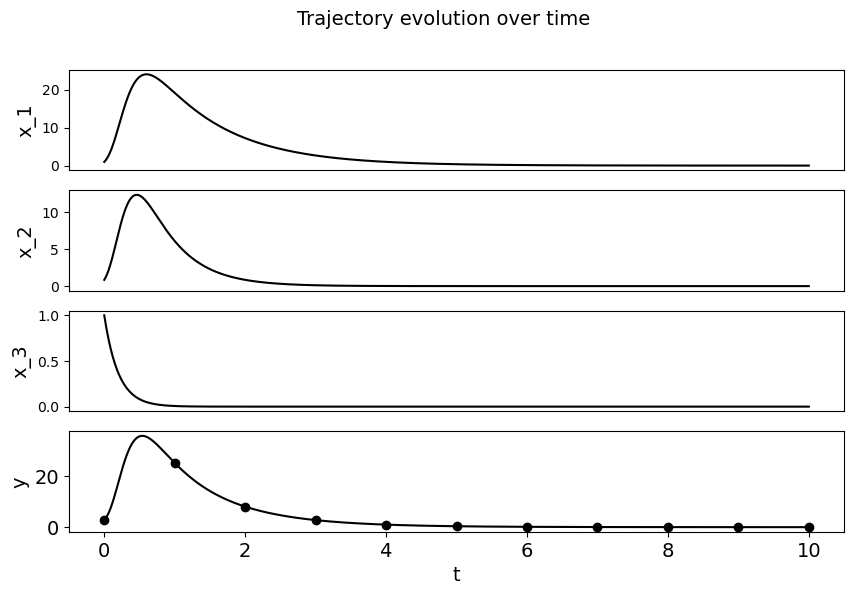

In [541]:
fig = plt.figure(figsize=(10,6))
fig.suptitle('Trajectory evolution over time', fontsize=14)
ax = fig.add_subplot(4,1,1)
ax.plot(traj_time, FOM_x_trajs[k][:,0], 'k-')
ax.set_ylabel('x_1', fontsize=14)
ax.set_xticks([])

ax = fig.add_subplot(4,1,2)
ax.plot(traj_time, FOM_x_trajs[k][:,1], 'k-')
ax.set_ylabel('x_2', fontsize=14)
ax.set_xticks([])

ax = fig.add_subplot(4,1,3)
ax.plot(traj_time, FOM_x_trajs[k][:,2], 'k-')
ax.set_ylabel('x_3', fontsize=14)
ax.set_xticks([])

ax = fig.add_subplot(4,1,4)
ax.plot(traj_time, FOM_y_trajs[k][:,0], 'k-')
ax.plot(t_data, y_traj_data[k][:,0], 'ko')
ax.set_ylabel('y', fontsize=14)
ax.set_xlabel('t', fontsize=14)
ax.tick_params(axis='both', labelsize=14)

k = (k + 1) % n_traj
plt.show()

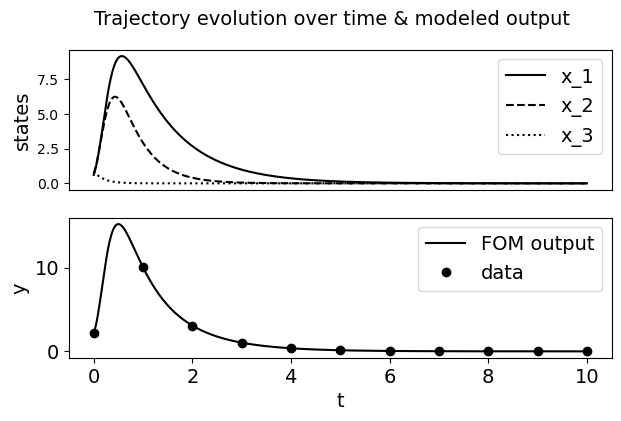

In [542]:
fig = plt.figure(figsize=(7,4))
fig.suptitle('Trajectory evolution over time & modeled output', fontsize=14)

# First plot: all states
ax = fig.add_subplot(2,1,1)
ax.plot(traj_time, FOM_x_trajs[k][:,0], 'k-', label='x_1')
ax.plot(traj_time, FOM_x_trajs[k][:,1], 'k--', label='x_2')
ax.plot(traj_time, FOM_x_trajs[k][:,2], 'k:', label='x_3')
ax.set_ylabel('states', fontsize=14)
ax.set_xticks([])
ax.legend(fontsize=14)

# Second plot: output
ax = fig.add_subplot(2,1,2)
ax.plot(traj_time, FOM_y_trajs[k][:,0], 'k-', label='FOM output')
ax.plot(t_data, y_traj_data[k][:,0], 'ko', label='data')
ax.set_ylabel('y', fontsize=14)
ax.set_xlabel('t', fontsize=14)
ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize=14)

k = (k + 1) % n_traj
plt.show()

In [543]:
# Generate 30 test initial conditions in the extrapolation range [1.0, 1.5].
np.random.seed(24)
n_traj_test = 30

Initial_condition_test_extrapolated = [np.random.uniform(1, 1.5, size=n_states) for _ in range(n_traj_test)]

In [544]:
# Generate 30 test initial conditions without extrapolation in the range [0.5, 1.0].
np.random.seed(24)
n_traj_test = 30

Initial_condition_test_no_extrapolation = [np.random.uniform(0.5, 1, size=n_states) for _ in range(n_traj_test)]

In [545]:
# System Setup
n = A_FOM.shape[0]
m = B_FOM.shape[1]
p = C_FOM.shape[0]

Q = np.eye(p)
# A large R penalizes control effort strongly.
R = 1e2 * np.eye(m)

# Time grid: Left Gauss-Radau nodes and weights.
t0, tf = 0.0, 10
N = 200
t, w = gauss_radau_left(N, a=t0, b=tf)

def pack_u(U):
    return U.reshape(-1)

def unpack_u(u_vec):
    return u_vec.reshape(N, m)

def make_u_fun(u_vec):
    U = unpack_u(u_vec)
    return BarycentricInterpolator(t, U, axis=0)

# Forward simulation of the nonlinear FOM.
# Use dense output so the solution can be evaluated at the quadrature nodes.
def forward_trajectory(u_vec,x0):
    u_fun = make_u_fun(u_vec)

    def f(tq, x):
        return FOM(x, u_fun(tq))  # Nonlinear dynamics.

    sol = solve_ivp(f, (t0, tf), x0, dense_output=True, method='RK45', rtol=rtol,atol=atol)
    return sol.sol  # Return the continuous solution x(t).

# Cost functional.
def total_cost(u_vec, X):
    U = unpack_u(u_vec)
    Y = (C_FOM @ X.T).T
    stage_y = np.einsum('ij,ij->i', Y @ Q, Y)
    stage_u = np.einsum('ij,ij->i', U @ R, U)
    J = np.dot(w, stage_y + stage_u)
    return J

# Gradient using the adjoint method.
def gradient(u_vec, X, return_adj=False):
    u_fun = make_u_fun(u_vec)

    def adj_rhs(tq, p):
        xq = X(tq)
        return - d_FOM_adj(xq, u_fun(tq), p) - 2 * d_FOM_obs_adj(xq, Q @ FOM_obs(xq))

    pT = np.zeros(n)
    sol = solve_ivp(lambda tq, p: adj_rhs(tq, p),
                    (tf, t0), pT, dense_output=True,
                    method='RK45', rtol=rtol, atol=atol)
    P = sol.sol(t).T  # Evaluate the continuous adjoint at the quadrature nodes.

    U = unpack_u(u_vec)
    BtP = np.array([B_FOM.T @ P[i] for i in range(len(P))])
    Gi = (BtP + 2.0 * (U @ R)) * w[:, None]

    if return_adj:
        return Gi.reshape(-1), P
    else:
        return Gi.reshape(-1)
    
# Objective and callbacks.
def objective_with_grad(u_vec,x0):
    X_fun = forward_trajectory(u_vec,x0)
    X = X_fun(t).T  # Evaluate the state trajectory at the quadrature nodes.
    J = total_cost(u_vec, X)
    g = gradient(u_vec, X_fun)
    return J, g

def fun_only(u_vec,x0):
    return objective_with_grad(u_vec,x0)[0]  # Return the cost.

def jac_only(u_vec,x0):
    return objective_with_grad(u_vec,x0)[1]  # Return the gradient with respect to the control parameters.

# Callback for logging iteration progress.
iteration_data = []

def callback(u_vec,x0):
    J, g = objective_with_grad(u_vec,x0)
    grad_norm = np.linalg.norm(g)
    iteration_data.append((len(iteration_data), J, grad_norm))
    print(f"Iter {len(iteration_data):3d}: Cost = {J:.6f}, ||grad|| = {grad_norm:.3e}")

In [546]:
def verify_adjoint_gradient(x0, N, m, t, forward_trajectory, gradient, total_cost, eps=1e-5):

    u_vec = np.random.randn(N * m)

    # Forward returns function and evaluate at quadrature nodes
    x_fun = forward_trajectory(u_vec, x0)
    X = x_fun(t).T

    # Adjoint gradient - pass function
    g_analytic = gradient(u_vec, x_fun)

    # Random direction
    v = np.random.randn(*u_vec.shape)
    v /= np.linalg.norm(v)

    adj_deriv = np.dot(g_analytic, v)

    # Cost at base point
    J0 = total_cost(u_vec, X)

    # Perturb control in the direction of v
    u_pert = u_vec + eps * v

    # Forward for perturbed control
    x_fun_pert = forward_trajectory(u_pert, x0)
    X_pert = x_fun_pert(t).T

    J1 = total_cost(u_pert, X_pert)

    # Finite difference check
    fd_deriv = (J1 - J0) / eps

    # Relative error
    rel_err = np.abs(adj_deriv - fd_deriv) / np.abs(fd_deriv)

    return rel_err, adj_deriv, fd_deriv

In [547]:
rel_err, adj_deriv, fd_deriv= verify_adjoint_gradient(x0, N, m, t, forward_trajectory, gradient, total_cost, eps=1e-5)
print("\nAdjoint Gradient Verification")
print(f"Adjoint directional derivative : {adj_deriv:.6e}")
print(f"Finite diff directional deriv. : {fd_deriv:.6e}")
print(f"Ratio (adj/fd)                 : {adj_deriv/(fd_deriv + 1e-12):.6f}")
print(f"Relative error                 : {rel_err:.6e}")

# Use a small relative error threshold.
if rel_err < 1e-3:
        print("✅ Gradient check PASSED")
else:
        print("⚠️ Gradient check FAILED")


Adjoint Gradient Verification
Adjoint directional derivative : -9.373342e+00
Finite diff directional deriv. : -9.374293e+00
Ratio (adj/fd)                 : 0.999899
Relative error                 : 1.014903e-04
✅ Gradient check PASSED


Iter   1: Cost = 97.175265, ||grad|| = 5.316e+01
Iter   2: Cost = 83.419271, ||grad|| = 5.301e+01
Iter   3: Cost = 83.152384, ||grad|| = 4.696e+01
Iter   4: Cost = 80.607955, ||grad|| = 4.473e+01
Iter   5: Cost = 75.918280, ||grad|| = 4.094e+01
Iter   6: Cost = 68.464749, ||grad|| = 3.385e+01
Iter   7: Cost = 59.966849, ||grad|| = 2.359e+01
Iter   8: Cost = 54.067818, ||grad|| = 1.524e+01
Iter   9: Cost = 50.767612, ||grad|| = 1.061e+01
Iter  10: Cost = 48.786952, ||grad|| = 7.841e+00
Iter  11: Cost = 47.557743, ||grad|| = 5.994e+00
Iter  12: Cost = 46.676216, ||grad|| = 4.475e+00
Iter  13: Cost = 46.194998, ||grad|| = 3.660e+00
Iter  14: Cost = 45.863427, ||grad|| = 2.734e+00
Iter  15: Cost = 45.725027, ||grad|| = 2.397e+00
Iter  16: Cost = 45.581538, ||grad|| = 1.686e+00
Iter  17: Cost = 45.519246, ||grad|| = 1.588e+00
Iter  18: Cost = 45.458106, ||grad|| = 1.050e+00
Iter  19: Cost = 45.445160, ||grad|| = 1.051e+00
Iter  20: Cost = 45.425752, ||grad|| = 8.045e-01
Iter  21: Cost = 45.

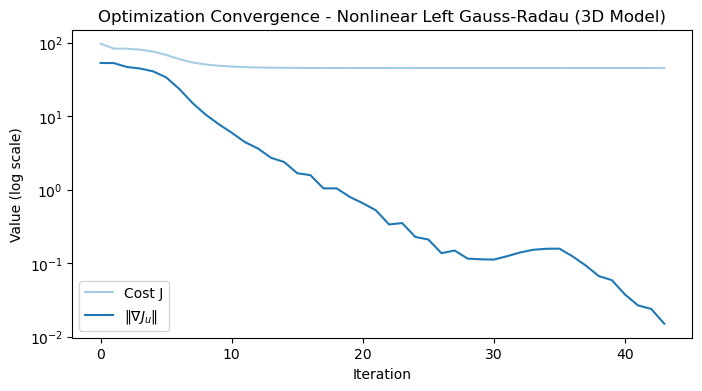

In [548]:
# Optimization
U0 = 0 * np.ones((N, m))   # Initial guess (zeros)
u0 = pack_u(U0)

# Minimize the cost function while passing the cost and gradient to BFGS.
res = minimize(fun_only, u0, args=(x0,), jac=jac_only, method='BFGS',
               tol=1e-6,
               options=dict(maxiter=800, gtol=1e-12, disp=True),
               callback=lambda u: callback(u, x0))

# Check why optimization stopped.
print("\n--- Optimizer Status ---")
print("Success:", res.success)
print("Message:", res.message)
print("Status:", res.status)
print("Iterations:", res.nit)
print("Function evaluations:", res.nfev)
print("Gradient evaluations:", res.njev)
print("Final gradient norm:", np.linalg.norm(res.jac))

# Store the optimal control and trajectory.
u_star = unpack_u(res.x)
X_star_fun = forward_trajectory(res.x,x0)
X = X_star_fun(t).T  # Evaluate the optimal state trajectory at the quadrature nodes.
J_star = total_cost(res.x, X)
Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)
print("\nOptimization complete.")
print("Final cost J* =", J_star)

# Plot convergence.
if iteration_data:
    iters, costs, grads = zip(*iteration_data)
    plt.figure(figsize=(8,4))
    plt.semilogy(iters, costs, label="Cost J")
    plt.semilogy(iters, grads, label=r"$\|\nabla J_u\|$")
    plt.xlabel("Iteration")
    plt.ylabel("Value (log scale)")
    plt.title("Optimization Convergence - Nonlinear Left Gauss-Radau (3D Model)")
    plt.legend()
    plt.minorticks_off()
    plt.grid(False)
    plt.show()

In [549]:
custom_colors = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c", "#000000"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=custom_colors)

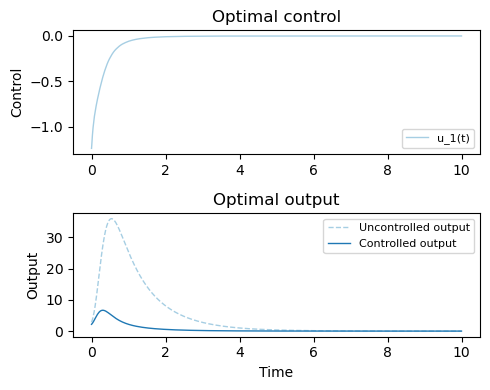

In [550]:
# Plot the optimal controls and model outputs from the Left Gauss-Radau solution.
Y_star = (C_FOM @ X.T).T
fig, axes = plt.subplots(2, 1, figsize=(5,4))

for j in range(u_star.shape[1]):
    axes[0].plot(t, u_star[:, j], label=f"u_{j+1}(t)", linewidth=1.0)
axes[0].set_ylabel("Control")
axes[0].set_title("Optimal control")
axes[0].legend(fontsize=8)
axes[0].grid(False)

for j in range(Y_star.shape[1]):
    axes[1].plot(traj_time, FOM_y_trajs[k][:, j], linestyle='--', label='Uncontrolled output', linewidth=1.0)
    axes[1].plot(t, Y_star[:, j], label='Controlled output', linewidth=1.0)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Output")
axes[1].set_title("Optimal output")
axes[1].legend(fontsize=8)
axes[1].grid(False)

plt.tight_layout()
plt.show()

In [551]:
# # Number of trajectories 
# n_samples_MC = 50

# # Optimization for Multiple Random Samples
# dataset_toy = []   
# optimization_times = []
# np.random.seed(42) 

# # Start total timer
# total_start = time.perf_counter()

# for k in range(n_samples_MC):
#     # Clear the screen
#     clear_output(wait=True) 
    
#     if k>0 :
#         prev_cost = dataset_toy[k-1]['cost']
#         prev_x0 = dataset_toy[k-1]['x0']
#         prev_time = dataset_toy[k-1]['optimization_time']
#         print(f"Previous Sample {k}: J* = {prev_cost:.6f}, x0 = {prev_x0}, optimization time = {prev_time:.2f} seconds")

#     else:
#         print("Starting first sample...")

#     print(f"Sample {k+1}/{n_samples_MC} running...")
    
#     # Reset iteration tracker
#     iteration_data = []

#     # Pick a uniform starting state in the 3D domain
#     x0 = np.random.uniform(0.5, 1, size=n_states)

#     print(f"Initial condition x0 = {x0} for iteration {k}")
    
#     # Initial control guess
#     U0 = 0 * np.ones((N, m))   # Initial guess (zeros)
#     u0 = pack_u(U0)

#     # Start timer for this optimization
#     opt_start = time.perf_counter()

#     # Run optimization for this initial condition 
#     res = minimize(
#         fun_only, u0,
#         args=(x0,),
#         jac=jac_only,
#         method='BFGS',
#         tol=1e-6,
#         options=dict(maxiter=800, gtol=1e-8, disp=False),
#         callback=lambda u: callback(u, x0)
#     )

#     # End timer for this optimization
#     opt_time = time.perf_counter() - opt_start
#     optimization_times.append(opt_time)

#     # Compute final trajectories and adjoints
#     u_star = unpack_u(res.x)
#     X_star_fun = forward_trajectory(res.x,x0)
#     X_star = X_star_fun(t).T                  # Evaluate at nodes - X_fun returns n by N and transpose to get N by n 
#     J_star = total_cost(res.x, X_star)
#     Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)

#     Y_star = (C_FOM @ X_star.T).T

#     # Stage cost (vectorized)
#     L = np.einsum('ij,ij->i', Y_star @ Q, Y_star) + \
#     np.einsum('ij,ij->i', u_star @ R, u_star)

#     # Value function (vectorized)
#     V = np.cumsum((w * L)[::-1])[::-1]

#     # Store structured dataset entry 
#     dataset_toy.append({
#         'x0': x0,
#         'state_history': X_star,
#         'control_history': u_star,
#         'gradient_history': P_star,
#         'cost': J_star,
#         'Value_function': V,
#         'optimization_time': opt_time,
#     })

# np.save("dataset_toy.npy", dataset_toy, allow_pickle=True)

In [552]:
# # Run the same optimization routine for both the non-extrapolated and extrapolated
# # test sets, and save each dataset under a distinct filename.

# def run_test_trajectory_optimizations(initial_conditions, filename, label='non_extrapolated'):

#     global iteration_data, callback_counter
#     iteration_data, callback_counter = [], 0

#     n_samples_test = len(initial_conditions)
#     dataset = []
#     optimization_times = []
#     total_start = time.perf_counter()

#     for k in range(n_samples_test):
#         clear_output(wait=True)
#         iteration_data = []
#         callback_counter = 0

#         if k > 0:
#             prev_cost = dataset[k-1]['cost']
#             prev_time = dataset[k-1]['optimization_time']
#             print(f"[{label}] Previous Sample {k}: J* = {prev_cost:.6f}, optimization time = {prev_time:.2f} seconds")
#         else:
#             print(f"[{label}] Starting first sample...")

#         print(f"[{label}] Sample {k+1}/{n_samples_test} running...")

#         iteration_data = []
#         x0 = initial_conditions[k]

#         print(f"[{label}] Initial condition for iteration {k}:")
#         print(x0)

#         U0 = 0 * np.ones((N, m))
#         u0 = pack_u(U0)

#         opt_start = time.perf_counter()
#         res = minimize(
#             fun_only, u0,
#             args=(x0,),
#             jac=jac_only,
#             method='BFGS',
#             tol=1e-6,
#             options=dict(maxiter=800, gtol=1e-8, disp=False),
#             callback=lambda u: callback(u, x0)
#         )
#         opt_time = time.perf_counter() - opt_start
#         optimization_times.append(opt_time)

#         u_star = unpack_u(res.x)
#         X_star_fun = forward_trajectory(res.x, x0)
#         X_star = X_star_fun(t).T
#         J_star = total_cost(res.x, X_star)
#         Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)

#         Y_star = (C_FOM @ X_star.T).T
#         L = np.einsum('ij,ij->i', Y_star @ Q, Y_star) + \
#             np.einsum('ij,ij->i', u_star @ R, u_star)
#         V = np.cumsum((w * L)[::-1])[::-1]

#         dataset.append({
#             'x0': x0,
#             'state_history': X_star,
#             'control_history': u_star,
#             'gradient_history': P_star,
#             'cost': J_star,
#             'Value_function': V,
#             'optimization_time': opt_time,
#         })

#         print(f"\n[{label}] Sample {k+1}/{n_samples_test} complete | J* = {J_star:.6f}")
#         print(f"[{label}] Optimization time = {opt_time:.2f} seconds")

#     total_time = time.perf_counter() - total_start
#     print(f"[{label}] Optimization from {n_samples_test} initial conditions done and completed")
#     print(f"[{label}] Total optimization time = {total_time:.2f} seconds")
#     print(f"[{label}] Average time per optimization = {np.mean(optimization_times):.2f} seconds")

#     np.save(filename, dataset, allow_pickle=True)
#     print(f"[{label}] Saved dataset to {filename}")
#     return dataset, optimization_times

# # Run the non-extrapolated case first.
# dataset_toy_test_no_extrapolation, optimization_times_test_no_extrapolation = run_test_trajectory_optimizations(
#     Initial_condition_test_no_extrapolation,
#     "dataset_toy_test_no_extrapolation.npy",
#     label='non_extrapolated'
# )

# # Then run the extrapolated case using the same code path.
# dataset_toy_test_extrapolated, optimization_times_test_extrapolated = run_test_trajectory_optimizations(
#     Initial_condition_test_extrapolated,
#     "dataset_toy_test_extrapolated.npy",
#     label='extrapolated'
# )

In [553]:
dataset = np.load("dataset_toy.npy", allow_pickle=True)

In [554]:
dataset_test_extrapolated = np.load("dataset_toy_test_extrapolated.npy", allow_pickle=True)
dataset_test_non_extrapolated = np.load("dataset_toy_test_no_extrapolation.npy", allow_pickle=True)

In [555]:
# J_all = [entry['cost'] for entry in dataset]

# J_min = np.min(J_all)
# J_max = np.max(J_all)
# J_range = J_max - J_min
# imin = np.argmin(J_all)
# imax = np.argmax(J_all)

# print("Index of min:", imin)
# print("Index of max:", imax)
# print("Min cost:", J_min)
# print("Max cost:", J_max)
# print("Difference:", J_range)

# samples = np.arange(1, len(J_all) + 1)
# plt.figure(figsize=(6, 4))
# plt.plot(samples, J_all, 'o-', linewidth=2)
# plt.xlabel("Trajectory sample")
# plt.ylabel("Optimal cost J")
# plt.title(f"Optimal Cost per Trajectory over {len(J_all)} Trajectories for Non-Linear Toy Model")
# plt.grid(True, linestyle="--", alpha=0.6)
# plt.show()

In [556]:
# Compute the controllability and observability Gramians and their square-root factors.
Wc = sp.linalg.solve_lyapunov(A_FOM, -np.dot(B_FOM, B_FOM.T))
Wo = sp.linalg.solve_lyapunov(A_FOM.T, -np.dot(C_FOM.T, C_FOM))

Uc, Sc, Vtc = np.linalg.svd(Wc, full_matrices=False)
Uo, So, Vto = np.linalg.svd(Wo, full_matrices=False)

# This factorization assumes Wc = Rc @ Rc.T and Wo = Ro @ Ro.T.
Rc = Uc @ np.diag(np.sqrt(Sc))
Ro = Uo @ np.diag(np.sqrt(So))

H_BT = Ro.T @ Rc

In [557]:
# Check that the Gramian factorizations reconstruct Wc and Wo accurately.
print(f"||Wc - Rc Rc^T|| = {np.linalg.norm(Wc - Rc @ Rc.T):.3e}")
print(f"||Wo - Ro Ro^T|| = {np.linalg.norm(Wo - Ro @ Ro.T):.3e}")

||Wc - Rc Rc^T|| = 2.502e-16
||Wo - Ro Ro^T|| = 2.502e-16


In [558]:
# SVD of the balanced-truncation Hankel matrix/product.
# H_BT = R_o^T R_c, where Wc = Rc Rc^T and Wo = Ro Ro^T.

H_BT = Ro.T @ Rc
U_BT, S_BT, Vt_BT = np.linalg.svd(H_BT, full_matrices=False)
energy_bt = np.cumsum(S_BT) / np.sum(S_BT)
r_maxbt = np.searchsorted(energy_bt, 0.99) + 1
print(f"Chosen r (99% energy) for balanced truncation: {r_maxbt}")

Chosen r (99% energy) for balanced truncation: 2


In [559]:
# Compute balanced-truncation bases for a chosen reduced dimension.
def compute_bt_basis(X, Y, U_BT, S_BT, Vt_BT, r):
    Ur = U_BT[:, :r]
    Sr = S_BT[:r]
    Vr = Vt_BT.T[:, :r]

    # Balanced primal and adjoint modes from the SVD of Y.T @ X.
    Phi = X @ Vr @ np.diag(1 / np.sqrt(Sr))
    Psi = Y @ Ur @ np.diag(1 / np.sqrt(Sr))

    return Phi, Psi

In [560]:
# Monte Carlo sampling: stack optimal gradients and state trajectories.
G_full = np.vstack([entry['gradient_history'] for entry in dataset])
X_full = np.vstack([entry['state_history'] for entry in dataset])

# Build the full time-weight matrix.
n_traj = len(dataset)
w_full = np.tile(w.reshape(-1, 1), (n_traj, 1))

print(f"G_full shape: {G_full.shape}")
print(f"X_full shape: {X_full.shape}")
print(f"w_full shape: {w_full.shape}")

# Apply quadrature weights in time.
G_full = G_full * np.sqrt(w_full)
X_full = X_full * np.sqrt(w_full)

# Normalize by the number of trajectories.
G_full /= np.sqrt(n_traj)
X_full /= np.sqrt(n_traj)

# Scale by the square root of the training interval length, 1 - 0.5 = 0.5.
G_full *= np.sqrt(0.5)
X_full *= np.sqrt(0.5)

print(f"Weighted G_full shape: {G_full.shape}")
print(f"Weighted X_full shape: {X_full.shape}")

G_full shape: (10000, 3)
X_full shape: (10000, 3)
w_full shape: (10000, 1)
Weighted G_full shape: (10000, 3)
Weighted X_full shape: (10000, 3)


In [561]:
# Compute SVDs of the weighted gradient and state snapshot matrices.
Ug, Sg, Vtg = np.linalg.svd(G_full, full_matrices=False)
Vg = Vtg.T

Ux, Sx, Vtx = np.linalg.svd(X_full, full_matrices=False)
Vx = Vtx.T

# Construct the factors used to form the BASOC Hankel matrix.
Rx = np.diag(Sx) @ Vx.T
Rg = np.diag(Sg) @ Vg.T

# Form and decompose the BASOC Hankel matrix.
H = Rg @ Rx.T
U_basoc, S_basoc, Vt_basoc = np.linalg.svd(H, full_matrices=False)

# Select the smallest rank containing 99% of the squared singular-value energy.
energy = np.cumsum(S_basoc**2) / np.sum(S_basoc**2)
r_basoc_max = np.searchsorted(energy, 0.99) + 1
print(f"Chosen BASOC rank (99% squared singular-value energy): {r_basoc_max}")

Chosen BASOC rank (99% squared singular-value energy): 2


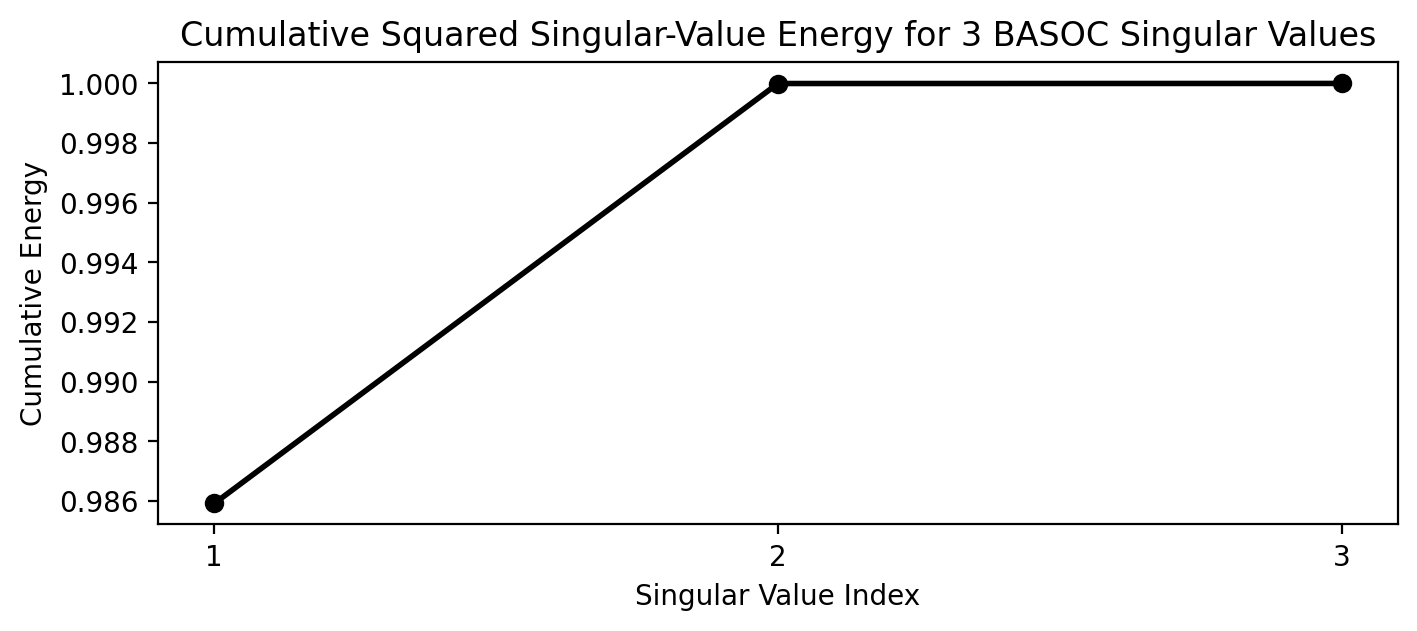

In [562]:
# Plot the cumulative squared singular-value energy for the first three BASOC modes.
K_evals_bal = n_states
evals_k = S_basoc[:K_evals_bal]
cum_energy = np.cumsum(evals_k**2) / np.sum(S_basoc**2)

plt.figure(figsize=(8, 3), dpi=200)
plt.plot(np.arange(1, K_evals_bal + 1), cum_energy, 'o-', linewidth=2, color='black')
plt.xlabel("Singular Value Index")
plt.ylabel("Cumulative Energy")
plt.title(f"Cumulative Squared Singular-Value Energy for {K_evals_bal} BASOC Singular Values")
plt.grid(False)
plt.xticks([1, 2, 3])
plt.show()

In [563]:
# Construct the BASOC primal and adjoint bases.
def compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r):
    U_r = U_basoc[:, :r]
    S_r = S_basoc[:r]
    V_r = Vt_basoc.T[:, :r]

    # Balanced primal and adjoint modes from Monte Carlo sampling.
    Phi_basoc = Rx.T @ V_r @ np.diag(1 / np.sqrt(S_r))
    Psi_basoc = Rg.T @ U_r @ np.diag(1 / np.sqrt(S_r))

    return Phi_basoc, Psi_basoc

In [564]:
# POD basis from optimal state trajectories.

Ux, Sx, Vtx = np.linalg.svd(X_full, full_matrices=False)
energy_x = np.cumsum(Sx**2) / np.sum(Sx**2)

# Select the rank containing 99% of the squared singular-value energy.

r_podmax = np.searchsorted(energy_x, 0.99) + 1
print(f"Optimal State POD rank (99% squared singular-value energy): {r_podmax}")

Optimal State POD rank (99% squared singular-value energy): 2


In [565]:
#Truncation for POD on optimal state trajectories 
def Pod_State_basis(Vtx, r):
    return Vtx[:r].T

In [566]:
# POD basis from optimal adjoint trajectories.

Ug, Sg, Vtg = np.linalg.svd(G_full, full_matrices=False)
energy_g = np.cumsum(Sg**2) / np.sum(Sg**2)

# Select the rank containing 99% of the squared singular-value energy.

r_g = np.searchsorted(energy_g, 0.99) + 1
print(f"Optimal Adjoint POD rank (99% squared singular-value energy): {r_g}")

Optimal Adjoint POD rank (99% squared singular-value energy): 1


In [567]:
# Truncation for POD on optimal Adjoint trajectories 
def Pod_Adjoint_basis(Vtg, r):
    return Vtg[:r].T

In [568]:
def Full_State_basis(n_states):
    return np.eye(n_states)

In [569]:
# Set the reduced-order model dimension.
r = 2

In [570]:
# Compute the BASOC primal and adjoint bases.
Phi_basoc, Psi_basoc = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)
print(f"Phi_basoc shape: {Phi_basoc.shape}")
print(f"Psi_basoc shape: {Psi_basoc.shape}")

Phi_basoc shape: (3, 2)
Psi_basoc shape: (3, 2)


In [571]:
# Compute the balanced-truncation primal and adjoint bases.
Phi_BT, Psi_BT = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r)
print(f"Phi_BT shape: {Phi_BT.shape}")
print(f"Psi_BT shape: {Psi_BT.shape}")

Phi_BT shape: (3, 2)
Psi_BT shape: (3, 2)


In [572]:
Phi_POD = Pod_State_basis(Vtx, r)
print("Phi shape for POD State:", Phi_POD.shape)

Phi shape for POD State: (3, 2)


In [573]:
Phi_POD_Adjoint = Pod_Adjoint_basis(Vtg, r)
print("Φ shape for POD Adjoint:", Phi_POD_Adjoint.shape)

Φ shape for POD Adjoint: (3, 2)


In [574]:
Phi_full_state = Full_State_basis(n_states)
print("Φ shape for Full State:", Phi_full_state.shape)

Φ shape for Full State: (3, 3)


In [575]:
# BT and BASOC use both Phi and Psi; POD uses only Phi with Galerkin projection.
names = ["BT", "POD State", "POD Adjoint", "BASOC"]

basis_name = names[3]
Phi_basis = Phi_basoc
Psi_basis = Psi_basoc

In [576]:
print(f"Phi shape for {basis_name}: {Phi_basis.shape}")
print(f"Psi shape for {basis_name}: {Psi_basis.shape}")

# Check biorthogonality.
M = Psi_basis.T @ Phi_basis
print(f"||Psi^T Phi - I|| for {basis_name}: {np.linalg.norm(M - np.eye(r)):.3e}")

Phi shape for BASOC: (3, 2)
Psi shape for BASOC: (3, 2)
||Psi^T Phi - I|| for BASOC: 3.027e-16


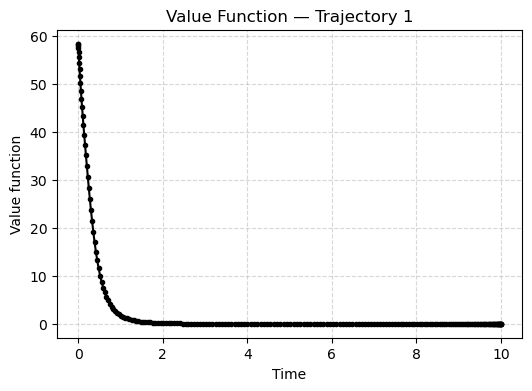

In [577]:
# Plot the stored value function for a selected optimized trajectory.
trajectory_number = 1  # Use one-based trajectory numbering.
value_function = dataset[trajectory_number - 1]['Value_function']

plt.figure(figsize=(6, 4))
plt.plot(t, value_function, '-o', color='black', linewidth=1.5, markersize=3)
plt.xlabel('Time')
plt.ylabel('Value function')
plt.title(f'Value Function — Trajectory {trajectory_number}')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [578]:
def project_dataset(dataset, Psi_basis):
    
    Y_list = [] # Projected states
    V_list = [] # Value function along trajectories
    U_list = [] # Optimal control along all trajectories 
    x0_all = [] # Initial conditions
    X_all = []  # Optimal state trajectories

    for data in dataset:

        X_k = data['state_history']
        X_all.append(X_k)

        V_k = data['Value_function']

        # Projection (depends on Psi_basis → depends on r)
        Y_k = X_k @ Psi_basis

        U_list.append(data['control_history'])
        x0_all.append(data['x0'])
        Y_list.append(Y_k)
        V_list.append(V_k.reshape(-1))

    Y = np.vstack(Y_list)
    V = np.concatenate(V_list).reshape(-1, 1)
    U = np.vstack(U_list)
    x0_all = np.vstack(x0_all)
    X = np.vstack(X_all)

    return Y, V, U, X, x0_all

In [579]:
Y, V, U, X, x0 = project_dataset(dataset, Psi_basis)

print(f"Dataset shapes for {basis_name}:")
print("Y shape:", Y.shape)
print("V shape:", V.shape)
print("U shape:", U.shape)
print("X shape:", X.shape)
print("x0 shape:", x0.shape)

Dataset shapes for BASOC:
Y shape: (10000, 2)
V shape: (10000, 1)
U shape: (10000, 1)
X shape: (10000, 3)
x0 shape: (50, 3)




In [580]:
fig, axes = plt.subplots(1, 3, figsize=(14,4), dpi=800)

for ax, basis_name in zip(axes, (names[0], names[1], names[3])):

    if basis_name == "BT":
        Phi, Psi = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r)
    elif basis_name == "POD State":
        Phi = Pod_State_basis(Vtx, r); Psi = Phi
    elif basis_name == "BASOC":
        Phi, Psi = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)

    Y, V, U, X, x0_all = project_dataset(dataset, Psi)

    sc = ax.scatter(Y[:,0], Y[:,1], c=V[:,0], s=5, cmap='viridis')
    ax.set_title(basis_name)
    ax.set_xlabel("Variable 1")
    ax.set_ylabel("Variable 2")

plt.subplots_adjust(right=0.90, wspace=0.35)

cax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
fig.colorbar(sc, cax=cax, label="Value Function V(x)")
plt.show()

In [581]:
warnings.filterwarnings("ignore")
def train_control_model_gpr(Y, U, k=2400, K_test=200):

    # Split
    Y_train, Y_test, U_train, U_test = train_test_split(Y, U, test_size=0.30, shuffle=False)

    # Model
    gpr = GaussianProcessRegressor(
        kernel = CK(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(),
        normalize_y = False,
    )

    # Train (subsample)
    gpr.fit(Y_train[:k, :], U_train[:k, :])

    # Predictions
    U_train_pred = gpr.predict(Y_train[:k, :])
    U_mean, U_std = gpr.predict(Y_test[:K_test, :], return_std=True)

    # Scores 
    r2_train = r2_score(U_train[:k, :], U_train_pred)
    r2_test  = r2_score(U_test[:K_test, :], U_mean)

    return (gpr, r2_train, r2_test)

gpr_model, r2_train_gpr, r2_test_gpr = train_control_model_gpr(Y, U, k=2400, K_test=200)
print(f"GPR Results for {basis_name} dim {r}:")
print("Train R² =", r2_train_gpr)
print("Test  R² =", r2_test_gpr)

GPR Results for BASOC dim 2:
Train R² = 0.9999895178430397
Test  R² = 0.9997634550433516


In [582]:
# Choose control model
control_model = gpr_model 

In [583]:
def learned_controller(x, Psi_basis, control_model):
    z = (x @ Psi_basis).reshape(1, -1)  # Reduce from 3 → r and reshape to (1, r)
    u = control_model.predict(z) 
    u = np.asarray(u).reshape(1, -1)    # Reshape controls into one row
    return u[0]                         # Output shape (1,) for the control input

In [584]:
def simulate_fullstate_surrogate_feedback(x0, Psi_basis, control_model):

    def f(time, x):
        return FOM(x, learned_controller(x, Psi_basis, control_model))

    sol = solve_ivp(f, (t0, tf), x0, t_eval=t, method="RK45", rtol=rtol, atol=atol)

    if not sol.success:
        raise RuntimeError(sol.message)

    X_traj, T_traj = sol.y.T, sol.t

    return X_traj, T_traj

### Real-time full-state feedback control.
The full FOM state is projected into reduced coordinates, $z=\Psi^\top x$. The trained Gaussian process predicts the control from these coordinates, and this control is applied to the FOM during the closed-loop simulation in real time. No state estimator is used.

```text
             ┌──────────────────────────┐
     û(z) ──▶│ Full-order model (Plant)  │── x ──┐
       ▲     └──────────────────────────┘       │
       │                                        ▼
┌───────────────────────┐       ┌───────────────────────────┐
│ Surrogate control law │◀── z ─│ Full-state projection Ψᵀx │
└───────────────────────┘       └───────────────────────────┘
```

In [585]:
Fullstate_feedback_names = names + ["Full_State"]

test_datasets = {
    "Non-extrapolated": dataset_test_non_extrapolated,
    "Extrapolated": dataset_test_extrapolated,
}

results_rombasedfeedback = {test_name: {name: {} for name in Fullstate_feedback_names} for test_name in test_datasets}

for test_name, test_dataset in test_datasets.items():

    for feedback_basis_name in Fullstate_feedback_names:

        r_values = [n_states] if feedback_basis_name == "Full_State" else [2]

        for r_feedback in r_values:

            print(f"\n--- {test_name}: {feedback_basis_name}, r={r_feedback} ---")

            if feedback_basis_name == "Full_State":
                Phi_basis_romfeedback = Full_State_basis(n_states)
                Psi_basis_romfeedback = Phi_basis_romfeedback

            elif feedback_basis_name == "BT":
                Phi_basis_romfeedback, Psi_basis_romfeedback = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r_feedback)

            elif feedback_basis_name == "POD State":
                Phi_basis_romfeedback = Pod_State_basis(Vtx, r_feedback)
                Psi_basis_romfeedback = Phi_basis_romfeedback

            elif feedback_basis_name == "POD Adjoint":
                Phi_basis_romfeedback = Pod_Adjoint_basis(Vtg, r_feedback)
                Psi_basis_romfeedback = Phi_basis_romfeedback

            elif feedback_basis_name == "BASOC":
                Phi_basis_romfeedback, Psi_basis_romfeedback = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r_feedback)

            Y, V, U, X, x0_all = project_dataset(dataset, Psi_basis_romfeedback)

            gpr_model, r2_train_gpr, r2_test_gpr = train_control_model_gpr(Y, U, k=2400, K_test=200)

            control_model = gpr_model

            J_rom_all = []
            err_all = []
            err_abs_rel_all = []

            for i, entry in enumerate(test_dataset):

                x0 = entry["x0"]
                J_true = entry["cost"]

                X_traj, T_traj = simulate_fullstate_surrogate_feedback(x0, Psi_basis_romfeedback, control_model)

                Z = X_traj @ Psi_basis_romfeedback

                U_star = control_model.predict(Z)

                # Replay controls using the trajectory optimization representation
                u_vec = pack_u(U_star)

                X_replay = forward_trajectory(u_vec, x0)(t).T

                J_fullstate_feedback = total_cost(u_vec, X_replay)

                error = J_fullstate_feedback - J_true

                error_abs_relative = abs(error) / J_true

                J_rom_all.append(J_fullstate_feedback)
                err_all.append(error)
                err_abs_rel_all.append(error_abs_relative)

                print(f"{test_name}, {feedback_basis_name}, r={r_feedback}, IC={i+1} → J_true={J_true:.8f}, J_rom={J_fullstate_feedback:.8f}, error={error:.8f}, abs_error={abs(error):.8f}, rel_error={error_abs_relative:.6e}")

            results_rombasedfeedback[test_name][feedback_basis_name][f"r={r_feedback}"] = {"J": J_rom_all, "err": err_all, "err_abs_rel": err_abs_rel_all, "r2_test": r2_test_gpr}

            print(f"\n{test_name}, {feedback_basis_name}, r={r_feedback} complete | median rel error={np.median(err_abs_rel_all):.6e}, mean rel error={np.mean(err_abs_rel_all):.6e}")


--- Non-extrapolated: BT, r=2 ---
Non-extrapolated, BT, r=2, IC=1 → J_true=105.55388308, J_rom=476.18365809, error=370.62977500, abs_error=370.62977500, rel_error=3.511285e+00
Non-extrapolated, BT, r=2, IC=2 → J_true=45.37354407, J_rom=51.76372626, error=6.39018219, abs_error=6.39018219, rel_error=1.408350e-01
Non-extrapolated, BT, r=2, IC=3 → J_true=20.07790899, J_rom=23.02737399, error=2.94946500, abs_error=2.94946500, rel_error=1.469010e-01
Non-extrapolated, BT, r=2, IC=4 → J_true=23.59517508, J_rom=26.06569962, error=2.47052454, abs_error=2.47052454, rel_error=1.047046e-01
Non-extrapolated, BT, r=2, IC=5 → J_true=46.71765515, J_rom=51.94081989, error=5.22316474, abs_error=5.22316474, rel_error=1.118028e-01
Non-extrapolated, BT, r=2, IC=6 → J_true=36.79523179, J_rom=41.97896804, error=5.18373625, abs_error=5.18373625, rel_error=1.408807e-01
Non-extrapolated, BT, r=2, IC=7 → J_true=74.40769648, J_rom=186.00760678, error=111.59991030, abs_error=111.59991030, rel_error=1.499844e+00
No

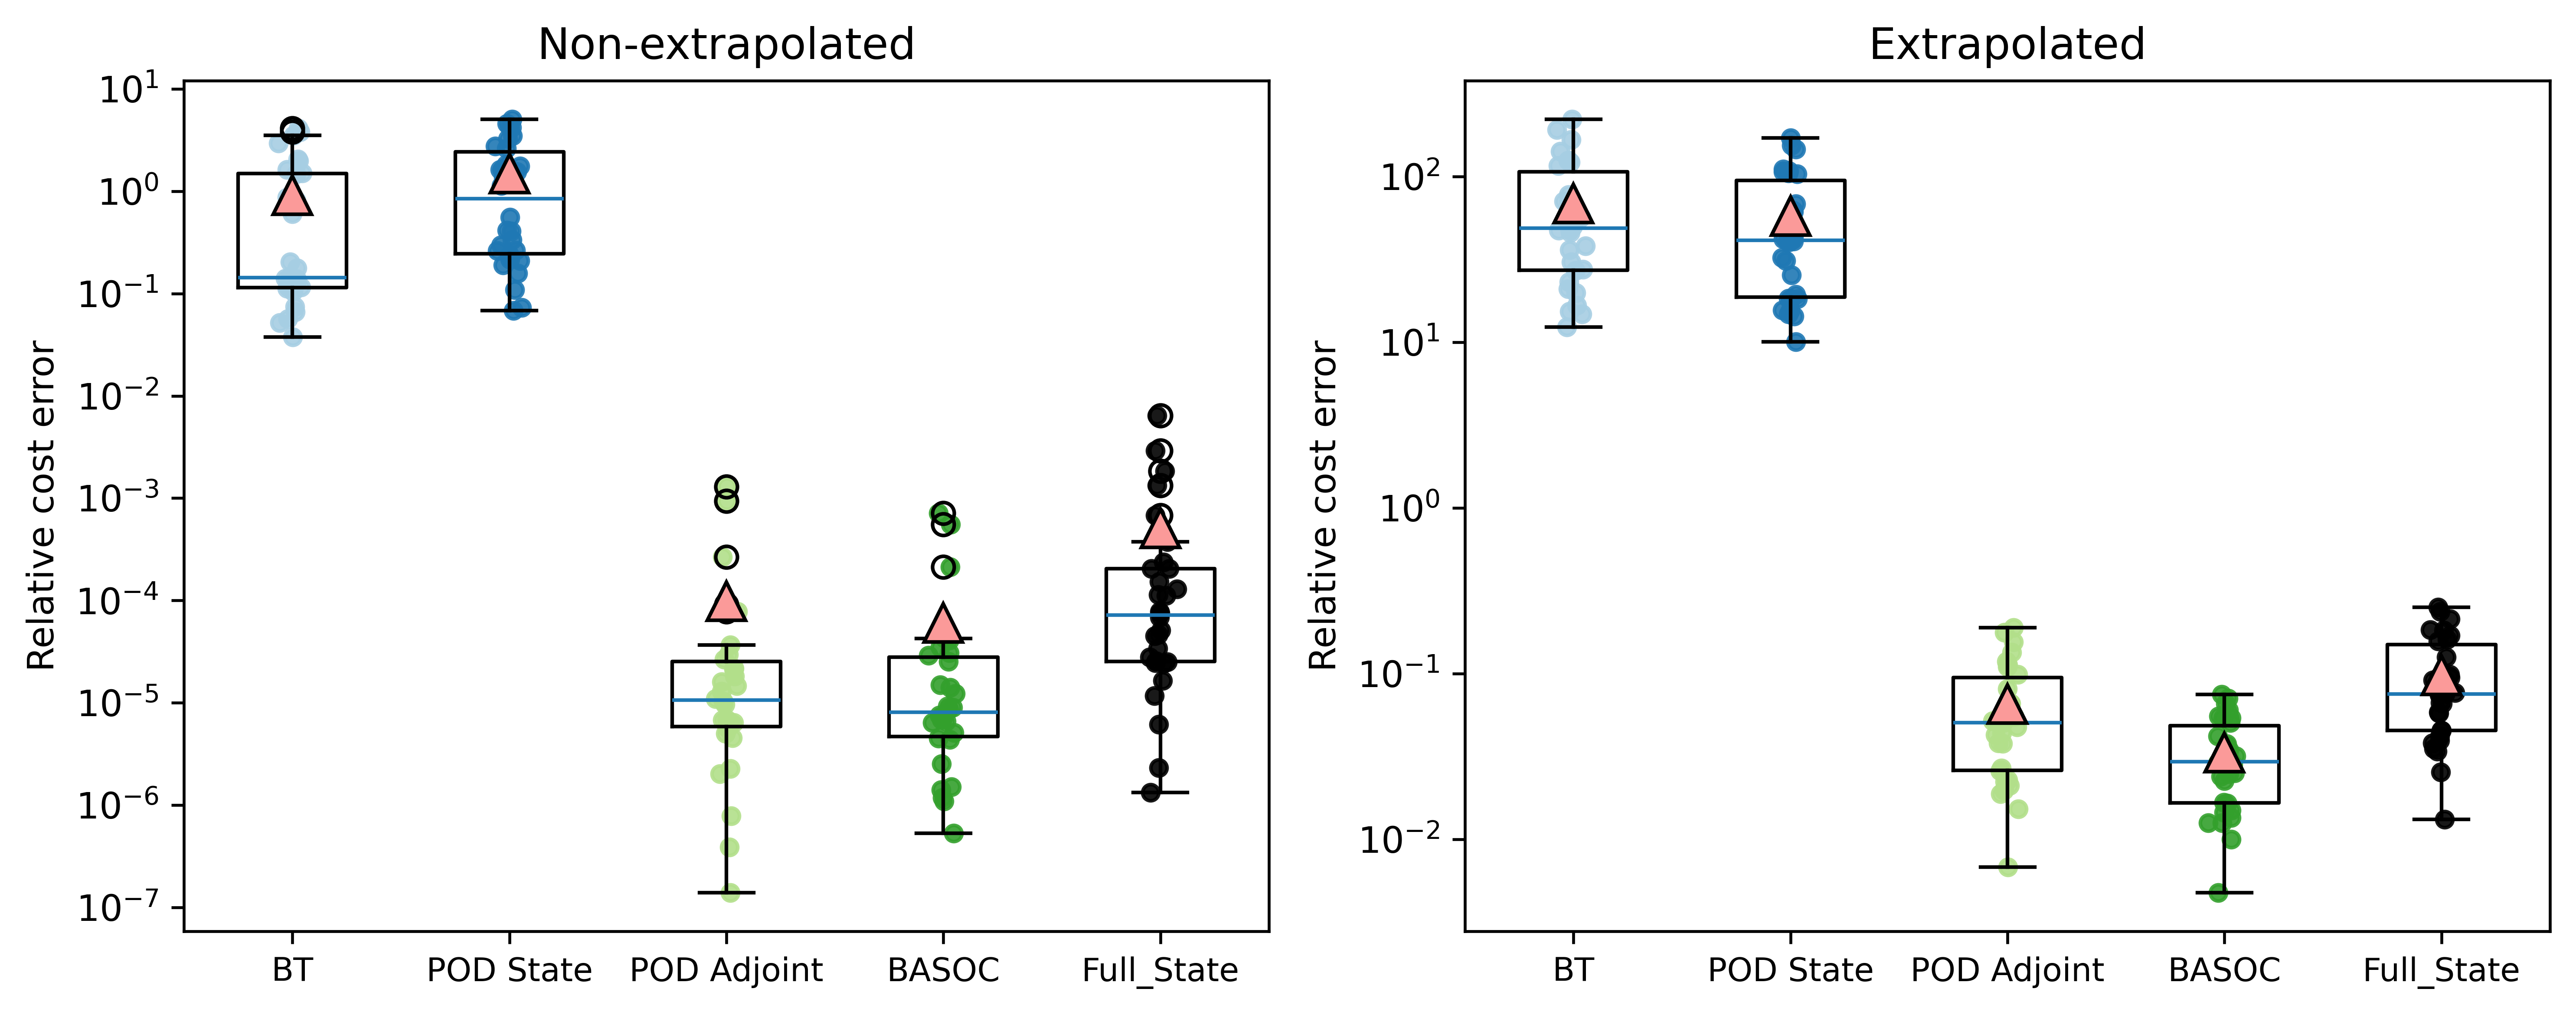

In [586]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=600)

for ax, test_name in zip(axes, test_datasets):
    errors = [results_rombasedfeedback[test_name][name][f"r={n_states if name == 'Full_State' else 2}"]["err_abs_rel"] for name in Fullstate_feedback_names]

    ax.boxplot(errors, tick_labels=Fullstate_feedback_names, showmeans=True, meanprops=dict(marker="^", markerfacecolor="#fb9a99", markeredgecolor="black", markersize=10.5))

    for i, (data, color) in enumerate(zip(errors, custom_colors), start=1):
        x = np.random.normal(i, 0.03, size=len(data))
        ax.scatter(x, data, color=color, alpha=0.9, s=20)

    ax.set_yscale("log")
    ax.set_title(test_name)
    ax.set_ylabel("Relative cost error")
    ax.tick_params(axis="x",  labelsize=9)
    ax.minorticks_off()

plt.tight_layout()
plt.show()

### Reduced-order model

The full-order model is

$$
\dot{x} = Ax + Bu + H(x,x), \qquad y = Cx,
$$

where $A \in \mathbb{R}^{n\times n}$, $B \in \mathbb{R}^{n\times m}$, $C \in \mathbb{R}^{p\times n}$, and $H \in \mathbb{R}^{n\times n\times n}$.

Using $x \approx \Phi z$ and $z = \Psi^\top x$, with $\Psi^\top\Phi = I_r$, projection gives

$$
\dot{z} = A_r z + B_r u + H_r(z,z), \qquad y_r = C_r z,
$$

where

$$
A_r = \Psi^\top A\Phi, \qquad B_r = \Psi^\top B, \qquad C_r = C\Phi,
$$

$$
H_r(z,z) = \Psi^\top H(\Phi z,\Phi z).
$$

The reduced dimensions are $A_r \in \mathbb{R}^{r\times r}$, $B_r \in \mathbb{R}^{r\times m}$, $C_r \in \mathbb{R}^{p\times r}$, and $H_r \in \mathbb{R}^{r\times r\times r}$.

For BASOC and BT, the projection $\Phi\Psi^\top$ is oblique: the trial and test bases differ but satisfy $\Psi^\top\Phi = I_r$. For POD State and POD Adjoint, $\Phi = \Psi$ with orthonormal columns, so the projection $\Phi\Phi^\top$ is orthogonal.

In [587]:
# Defining the ROM

def get_ROM_tensors(Phi, Psi , A_FOM, B_FOM , C_FOM, H_FOM):

    A_ROM = np.einsum('ji, jk, kl', Psi, A_FOM, Phi)
    B_ROM = np.einsum('ji, jk', Psi, B_FOM)
    C_ROM = np.einsum('ij, jk', C_FOM, Phi)
    H_ROM = np.einsum('ji,jkl,km,ln', Psi, H_FOM, Phi, Phi)
    return A_ROM, B_ROM, C_ROM, H_ROM

A_ROM, B_ROM, C_ROM, H_ROM = get_ROM_tensors(Phi_basis, Psi_basis, A_FOM, B_FOM, C_FOM, H_FOM)

print(f"A_ROM shape for {basis_name}: {A_ROM.shape}")  # r x r  
print(f"B_ROM shape for {basis_name}: {B_ROM.shape}")  # r x m
print(f"C_ROM shape for {basis_name}: {C_ROM.shape}")  # p x r
print(f"H_ROM shape for {basis_name}: {H_ROM.shape}")  # r x r x r

A_ROM shape for BASOC: (2, 2)
B_ROM shape for BASOC: (2, 1)
C_ROM shape for BASOC: (1, 2)
H_ROM shape for BASOC: (2, 2, 2)


### Open-loop ROM-based forecasting

The ROM is initialized with $z_0=\Psi^\top x_0$ and simulated using the prescribed optimal control $u^*(t)$ from the selected test trajectory. The reduced state is lifted to the full-state space using $\hat{x}(t)=\Phi z(t)$ and compared with the FOM trajectory under the same control. No feedback is used during forecasting.

```text
        ┌─────────────────────┐       ┌─────┐
u*(t) ─▶│ Reduced-order model │── z ──▶│  Φ  │──▶ x̂
        └─────────────────────┘       └─────┘
```

In [626]:
# ROM simulation along optimal trajectory 

def forward_trajectory_ROM(u_traj, z_init, A_ROM, B_ROM, H_ROM):
    
    u_fun = make_u_fun(u_traj)

    def f_ROM(tq, z):

        u = u_fun(tq)
        return A_ROM @ z + B_ROM @ u + np.einsum("ijk,j,k->i", H_ROM, z, z)

    sol_rom = solve_ivp(f_ROM, (t0, tf), z_init, t_eval=t, method="RK45", rtol=rtol, atol=atol)

    return sol_rom.y.T  # (Nt, r)

In [627]:
def compute_rom_error(solution_rom, Phi_basis, solution_fom, C_FOM, C_ROM):
    
    # Lift ROM to full space 
    x_rom_lifted = solution_rom @ Phi_basis.T

    # State error 
    state_error = np.linalg.norm(solution_fom - x_rom_lifted, 'fro') / np.linalg.norm(solution_fom, 'fro')

    # Output error 
    Y_fom = solution_fom @ C_FOM.T
    Y_rom = solution_rom @ C_ROM.T

    output_error = np.linalg.norm(Y_fom - Y_rom, 'fro') / np.linalg.norm(Y_fom, 'fro')

    return state_error, output_error

In [624]:
r_forecast = 2
test_dataset = dataset_test_extrapolated

all_state_errors, all_output_errors, all_y_rom = {}, {}, {}
all_y_fom = [entry["state_history"] @ C_FOM.T for entry in test_dataset]

for forecast_basis_name in names:

    if forecast_basis_name == "BT":
        Phi, Psi = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r_forecast)

    elif forecast_basis_name == "POD State":
        Phi = Pod_State_basis(Vtx, r_forecast)
        Psi = Phi

    elif forecast_basis_name == "POD Adjoint":
        Phi = Pod_Adjoint_basis(Vtg, r_forecast)
        Psi = Phi

    elif forecast_basis_name == "BASOC":
        Phi, Psi = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r_forecast)

    A_r, B_r, C_r, H_r = get_ROM_tensors(Phi, Psi, A_FOM, B_FOM, C_FOM, H_FOM)

    state_errors, output_errors, y_rom_all = [], [], []

    for entry in test_dataset:

        z_init = Psi.T @ entry["x0"]
        solution_rom = forward_trajectory_ROM(entry["control_history"], z_init, A_r, B_r, H_r)

        state_err, output_err = compute_rom_error(solution_rom, Phi, entry["state_history"], C_FOM, C_r)

        state_errors.append(state_err)
        output_errors.append(output_err)
        y_rom_all.append(solution_rom @ C_r.T)

    all_state_errors[forecast_basis_name] = state_errors
    all_output_errors[forecast_basis_name] = output_errors
    all_y_rom[forecast_basis_name] = y_rom_all

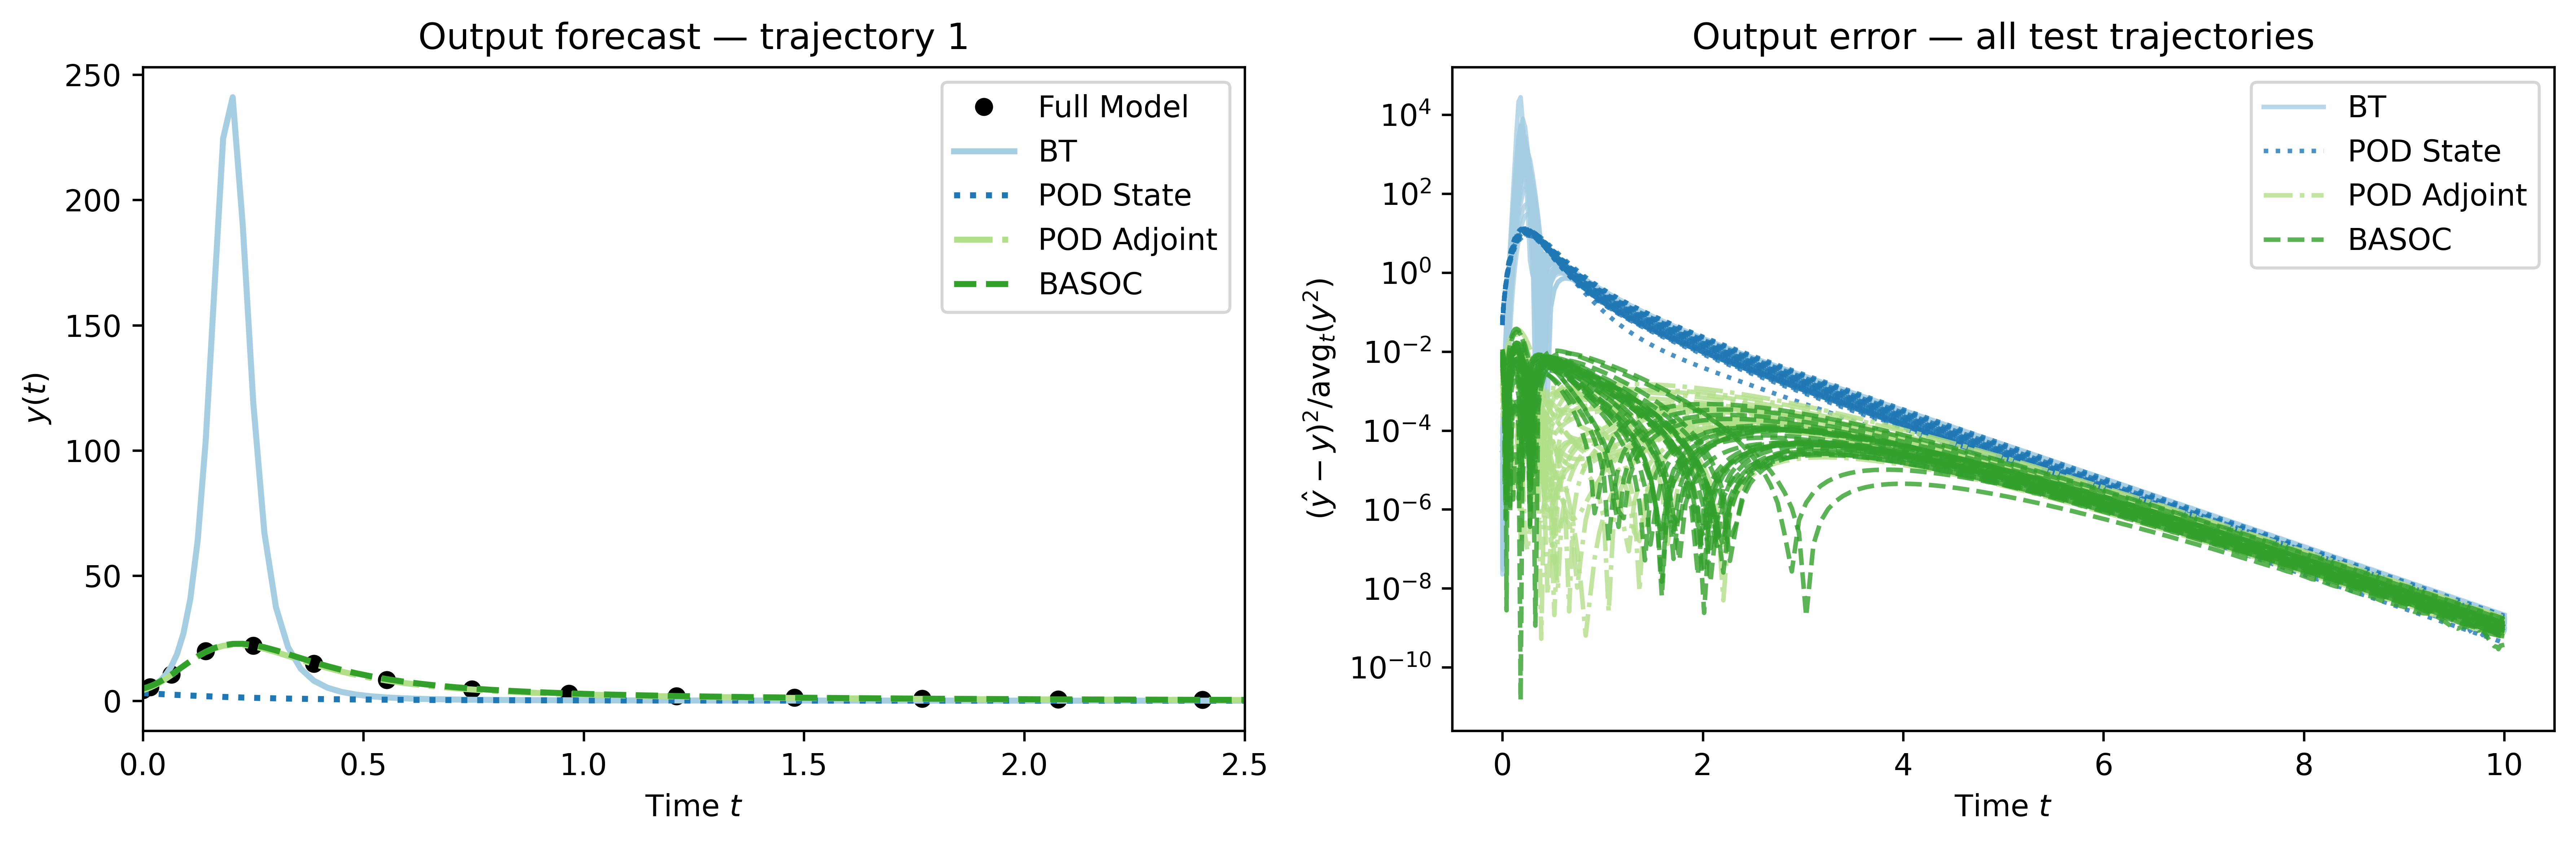

In [625]:
traj_id = 0
line_styles = ["-", ":", "-.", "--"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=600)

axes[0].plot(t, all_y_fom[traj_id][:, 0], color="black", linestyle="None",
             marker="o", markevery=5, markersize=5, label="Full Model")

for name, color, style in zip(names, custom_colors, line_styles):

    axes[0].plot(t, all_y_rom[name][traj_id][:, 0], color=color, linestyle=style, linewidth=2, label=name)

    for j, y_fom in enumerate(all_y_fom):
        y = y_fom[:, 0]
        error = (all_y_rom[name][j][:, 0] - y)**2 / np.mean(y**2)
        axes[1].plot(t, error, color=color, linestyle=style, alpha=0.8, linewidth=1.5,
                     label=name if j == 0 else None)

axes[0].set_title(f"Output forecast — trajectory {traj_id + 1}")
axes[0].set_ylabel(r"$y(t)$")
axes[0].set_xlim(0, 2.5)

axes[1].set_title("Output error — all test trajectories")
axes[1].set_ylabel(r"$(\hat y-y)^2/\mathrm{avg}_t(y^2)$")
axes[1].set_yscale("log")

for ax in axes:
    ax.set_xlabel("Time $t$")
    ax.legend()
    ax.minorticks_off()

plt.tight_layout()
plt.show()

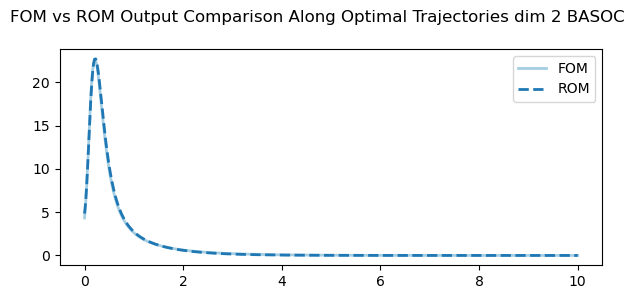

In [623]:
def plot_fom_vs_rom_outputs(C_FOM, C_ROM, X_fom, solution_rom, t):

    # Compute outputs
    Y_fom = (C_FOM @ X_fom.T).T
    Y_rom = (C_ROM @ solution_rom.T).T

    fig, ax = plt.subplots(figsize=(6,3))

    # Output 1
    ax.plot(t, Y_fom[:, 0], label='FOM', linewidth=2)
    ax.plot(t, Y_rom[:, 0], '--', label='ROM', linewidth=2)
    ax.legend()

    plt.suptitle(f"FOM vs ROM Output Comparison Along Optimal Trajectories dim {r} {basis_name}")
    plt.tight_layout()
    plt.show()

plot_fom_vs_rom_outputs(C_FOM, C_ROM, solution_fom, solution_rom, t)